In [ ]:
# ----------------- LIBRERÍAS -----------------
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [139]:
#Raúl
import pandas as pd # Estructura y manipulación de datos
url='/content/drive/MyDrive/Machine Learning/Prueba 2/Anexo ET_demo_round_traces_2022.csv'
df = pd.read_csv(url, sep=";", encoding='utf-8')


In [ ]:
#Sofia
url = '/content/drive/MyDrive/Fundamentos de machine learning/Anexo ET_demo_round_traces_2022.csv'
df = pd.read_csv(url, sep=";", encoding='utf-8')


In [140]:
#Con esta linea de codigo podemos asegurarnos de que las variables a utilizar sean numericas
df['MatchAssists'] = pd.to_numeric(df['MatchAssists'], errors='coerce')
df['TimeAlive'] = pd.to_numeric(df['TimeAlive'], errors='coerce')
df['MatchHeadshots'] = pd.to_numeric(df['MatchHeadshots'], errors='coerce')
df['RoundKills'] = pd.to_numeric(df['RoundKills'], errors='coerce')

In [141]:
# 3.1. Imputar NaN en columnas numéricas usando la media
import numpy as np # Programación vectorial
num_cols = df.select_dtypes(include=[np.number]).columns

for col in num_cols:
    if df[col].isnull().sum() > 0:
        mean_value = df[col].mean()
        df[col].fillna(mean_value, inplace=True)

In [142]:
# 3.2.En columnas categóricas rellenamos con el valor más frecuente
cat_cols = df.select_dtypes(include=['object']).columns

for col in cat_cols:
    if df[col].isnull().sum() > 0:
        mode_value = df[col].mode()[0]
        df[col].fillna(mode_value, inplace=True)

In [143]:
import pandas as pd
from imblearn.over_sampling import SMOTE

# 1. Limpieza y filtrado de Survived y AbnormalMatch
df['Survived'] = df['Survived'].astype(str).str.strip()
df = df[df['Survived'].isin(['True', 'False'])].copy()
df['Survived'] = df['Survived'].map({'True': 1, 'False': 0})
df = df[df['AbnormalMatch'] == False]


# 6. Selección de variables para modelo
X = df[['RLethalGrenadesThrown', 'RNonLethalGrenadesThrown','RoundKills',]].copy()
y = df['Survived']

# 7. Verificar nulos y shapes
print("Valores únicos en y:", y.unique())
print("¿Hay nulos en y?", y.isna().any())
print("¿Hay nulos en X?", X.isna().any().any())
print("Shape de X:", X.shape)
print("Shape de y:", y.shape)

# 8. Aplicar SMOTE
sm = SMOTE(random_state=42)
X_res, y_res = sm.fit_resample(X, y)

print("Distribución después de SMOTE:")
print(y_res.value_counts())


Valores únicos en y: [0 1]
¿Hay nulos en y? False
¿Hay nulos en X? False
Shape de X: (79157, 3)
Shape de y: (79157,)
Distribución después de SMOTE:
Survived
0    47214
1    47214
Name: count, dtype: int64


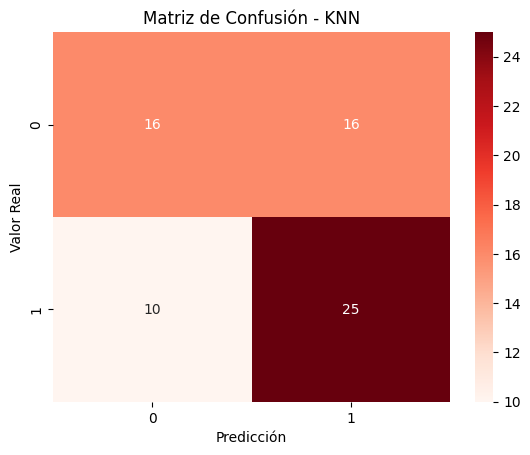

Reporte de Clasificación - KNN
              precision    recall  f1-score   support

           0       0.62      0.50      0.55        32
           1       0.61      0.71      0.66        35

    accuracy                           0.61        67
   macro avg       0.61      0.61      0.60        67
weighted avg       0.61      0.61      0.61        67



In [144]:
# ----------------- ENTRENAMIENTO KNN -----------------
modelo_knn = KNeighborsClassifier(n_neighbors=5)
modelo_knn.fit(X_train, y_train)

y_pred_knn = modelo_knn.predict(X_test)

matriz_knn = confusion_matrix(y_test, y_pred_knn)
sns.heatmap(matriz_knn, annot=True, fmt='d', cmap='Reds')
plt.title("Matriz de Confusión - KNN")
plt.xlabel("Predicción")
plt.ylabel("Valor Real")
plt.show()

print("Reporte de Clasificación - KNN")
print(classification_report(y_test, y_pred_knn))

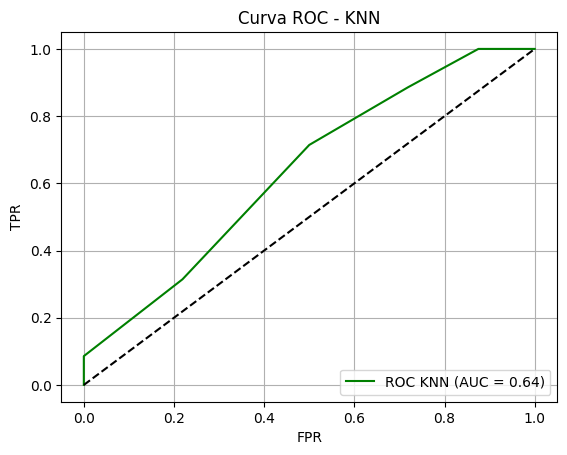

In [145]:
# ----------------- CURVA ROC -----------------
y_probs_knn = modelo_knn.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_probs_knn)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, label=f"ROC KNN (AUC = {roc_auc:.2f})", color="green")
plt.plot([0, 1], [0, 1], 'k--')
plt.title("Curva ROC - KNN")
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

Precision: de todas las veces que el modelo predijo victoria (1), acertó el 61%. Y cuando predijo derrota (0), acertó el 58%.

Recall: de todas las veces que el resultado real fue victoria, el modelo identificó correctamente el 63% de ellas. Para las derrotas, acertó el 56%.

F1-score: combina precisión y recall en una sola métrica. En general, el modelo tiene un F1 moderado (~60%) para ambas clases, lo que indica que está razonablemente equilibrado.

Accuracy general: el modelo acierta en el 60% de los casos.



Variables incluidas en la matriz de correlación:
['Unnamed: 0', 'InternalTeamId', 'MatchId', 'RoundId', 'RoundWinner', 'MatchWinner', 'Survived', 'AbnormalMatch', 'TimeAlive', 'RLethalGrenadesThrown', 'RNonLethalGrenadesThrown', 'PrimaryAssaultRifle', 'PrimarySniperRifle', 'PrimaryHeavy', 'PrimarySMG', 'PrimaryPistol', 'RoundKills', 'RoundAssists', 'RoundHeadshots', 'RoundFlankKills', 'RoundStartingEquipmentValue', 'TeamStartingEquipmentValue', 'MatchKills', 'MatchFlankKills', 'MatchAssists', 'MatchHeadshots']


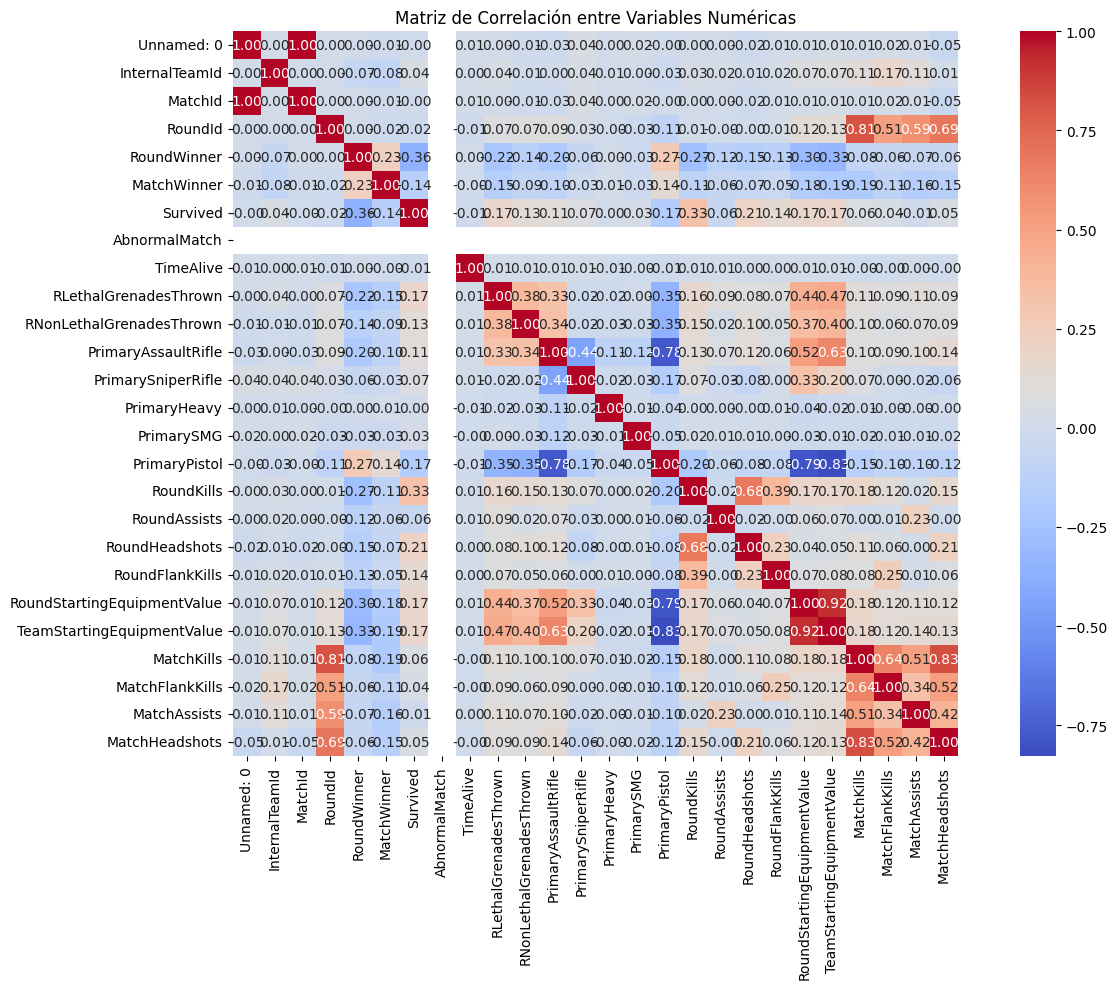

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Calcular la matriz de correlación directamente desde el DataFrame original
correlacion = df.corr(numeric_only=True)  # numeric_only=True es implícito en pandas >= 1.5

# Mostrar qué columnas están siendo incluidas
print("Variables incluidas en la matriz de correlación:")
print(correlacion.columns.tolist())

# Generar el heatmap
plt.figure(figsize=(14, 10))
sns.heatmap(correlacion, annot=True, fmt=".2f", cmap="coolwarm", square=True)
plt.title("Matriz de Correlación entre Variables Numéricas")
plt.tight_layout()
plt.show()


In [85]:
# 1. Asegurar que los valores son cadenas sin espacios
df['Survived'] = df['Survived'].astype(str).str.strip()

# 2. Filtrar solo valores válidos (por ejemplo 'True' o 'False')
df = df[df['Survived'].isin(['True', 'False'])].copy()

# 3. Convertir 'True' a 1 y 'False' a 0
df['Survived'] = df['Survived'].map({'True': 1, 'False': 0})

df = df[df['AbnormalMatch'] == False]

print(df['Survived'].unique())

[0 1]


Correlación de 'Survived' con las demás variables:
Survived                       1.000000
RoundKills                     0.331619
RoundHeadshots                 0.205279
TeamStartingEquipmentValue     0.173237
RLethalGrenadesThrown          0.171732
RoundStartingEquipmentValue    0.170578
RoundFlankKills                0.139673
RNonLethalGrenadesThrown       0.125064
PrimaryAssaultRifle            0.110008
PrimarySniperRifle             0.067100
MatchKills                     0.059445
MatchHeadshots                 0.047407
InternalTeamId                 0.044872
MatchFlankKills                0.041533
PrimarySMG                     0.026469
PrimaryHeavy                   0.002006
MatchId                       -0.003239
Unnamed: 0                    -0.003245
MatchAssists                  -0.008001
TimeAlive                     -0.008720
RoundId                       -0.015361
RoundAssists                  -0.063264
MatchWinner                   -0.143498
PrimaryPistol                

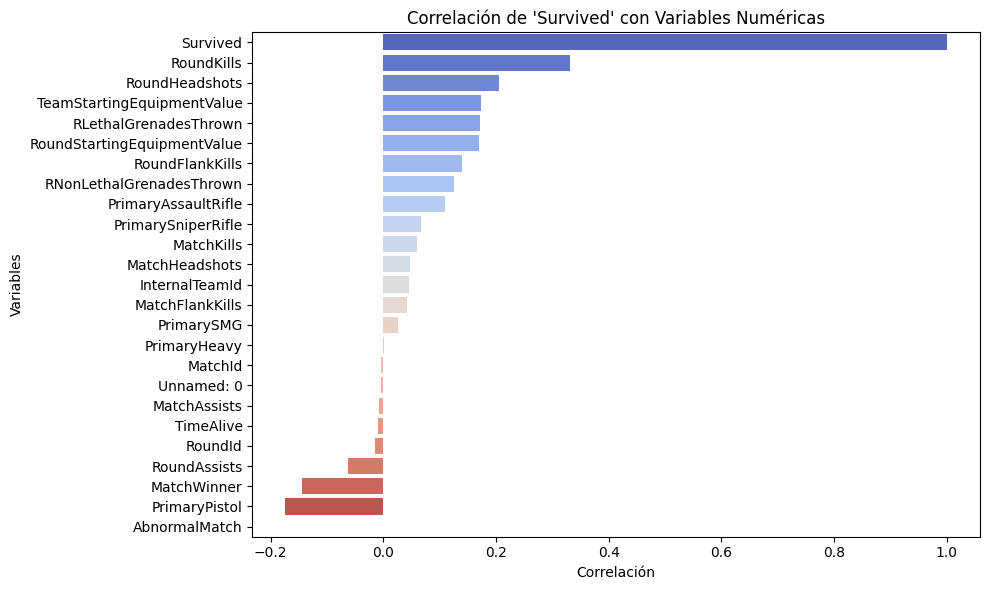

In [86]:
import seaborn as sns
import matplotlib.pyplot as plt

# Calcular la matriz de correlación completa
correlacion = df.corr(numeric_only=True)

# Mostrar solo las correlaciones con 'Survived'
correlacion_survived = correlacion['Survived'].sort_values(ascending=False)

# Mostrar por consola
print("Correlación de 'Survived' con las demás variables:")
print(correlacion_survived)

# Opcional: visualización como barra horizontal
plt.figure(figsize=(10, 6))
sns.barplot(x=correlacion_survived.values, y=correlacion_survived.index, palette="coolwarm")
plt.title("Correlación de 'Survived' con Variables Numéricas")
plt.xlabel("Correlación")
plt.ylabel("Variables")
plt.tight_layout()
plt.show()
